### 치이카와 유튜브 EDA v3

이번 분석의 대상은 한국어 이용자를 대상으로 한 치이카와 관련 콘텐츠다. 프로젝트의 관심은 국내 소비 양상이지만, 이 데이터에는 시청자 국가별 조회수가 없다.

그래서 영상을 ‘한국에서 실제로 소비된 영상’이라고 부르지 않고, 조회수를 ‘국내 조회수’라고 부르지 않는다. 한국 지역 검색, 한글이 들어간 제목, 채널 국가만으로 국내 소비를 확정하지 않는다. 조회수는 수집된 영상의 조회수다.

`04. youtube_EDA_v2.ipynb`와 원본 CSV는 변경하지 않는다. 판정표는 `relevance_review_v3`에 저장한다.


## 지금 자료로 확인할 수 있는 범위

분석 표와 관련성 감사 표에 있는 것은 채널, 제목, 설명, 태그, 게시 시각, 길이, 조회수, 좋아요, 댓글, 명칭이 맞은 필드다.

자막, 영상 속 발화, 썸네일, 화면, 시청자 국가는 없다. relevant 13,383편 중 설명은 6,557편이 비어 있다. 자동 번역과 제작자가 쓴 한국어를 가를 열도 없다.

판정은 제목·설명·태그로만 한다. 화면을 봤다고 쓰지 않는다. 그 텍스트로 장면, 상품, 대상 이용자가 갈리지 않으면 보류다.


## v2에서 버린 기준

v2는 제목에 한글이 있고 일본어 가나가 없으면 분석에 넣었다. 한글 해시태그가 붙은 외국어 제목은 통과하고, 한국어 문장 옆에 `ちいかわ`가 있으면 빠진다.

그래서 `#치이카와 #인형계`만 붙은 영상이 한국어 대상 영상으로 들어갔다. 조회수가 큰 예는 제목 본문이 `rainbow friends`인 영상이다. 사용자가 무관하다고 본 채널도 이 형태다.

작품 이름이 보인 것과 작품을 다룬 것은 다르다. `#인형계`가 보인 것과 인형 놀이를 확인한 것도 다르다. v2의 단어 빈도표는 문자열 언급량으로만 남긴다.


## 관련성과 대상 이용자는 따로 판정한다

| 판정 | 값 | 텍스트에서 두는 기준 |
| --- | --- | --- |
| A. 치이카와 관련성 | 관련 | 제목 본문이나 설명 문장이 작품·캐릭터의 장면, 상품, 행사, 창작을 말한다. 다른 IP와 같이 나와도 치이카와가 들어가면 관련일 수 있다 |
| A | 무관 | 사용자가 그 채널을 무관하다고 확인한 경우. 해시태그만 보고 무관으로 만들지 않는다 |
| A | 불명확 | 명칭이 해시태그·태그에만 있거나, 명칭 말고 내용 문장이 없다 |
| B. 한국어 이용자 대상 | 확인 | 해시태그, 캐릭터 이름, 상품명을 뺀 뒤에도 한국어 서술이 남는다 |
| B | 비대상 | 그런 한국어 서술이 없고, 공식 일본어 방송 안내이거나 다른 IP의 영어 제목, 다른 언어 문장이다 |
| B | 불명확 | 대상 언어를 정할 문장이 없다. 다른 언어가 섞였다는 이유만으로 빼지 않는다 |

주 분석은 A가 관련이고 B가 확인인 영상이다. A가 무관이거나 B가 비대상이면 이번 범위에서 빼되, 사유를 나눈다. 그 외는 보류다. 보류를 무관으로 세지 않는다.

이 집합은 근거가 있는 부분집합이다. 국내 콘텐츠 전체를 대표하지 않는다.

세 채널의 무관 판정은 사용자 확인 기록이다. 해시태그 모양이 비슷하다는 이유만으로 다른 채널까지 무관으로 넘기지 않는다.


## 9종 유형의 정의

v2의 ‘보유 후 놀이’는 ‘팬 창작·놀이’로 이름을 바꾼다. 더빙, 팬아트, 그리기, 만들기는 인형을 산 뒤의 놀이와 같지 않다. 인형으로 상황극을 하는 영상은 이 유형에 들어가지만, 구매 사실 자체는 조건이 아니다.

키워드는 후보만 만든다. 제목 본문이 그 활동을 말할 때만 확정한다. 해시태그만 있으면 확정하지 않는다. 본편 회차 제목에 붙은 빵, 과자, 핫케이크는 식음으로 확정하지 않는다. ‘인형이 된’ 장면은 굿즈가 아니다. 9종에 안 맞으면 미분류로 둔다.

| 유형 | 확정하는 내용 | 넣지 않는 예 | 겹칠 수 있는 경우 |
| --- | --- | --- | --- |
| 굿즈 | 인형, 키링, 피규어, 스티커, 쿠션 등을 사거나 열고 보여주는 영상 | 회차 안에서 인형이 된 장면. 인형뽑기 문구 속의 인형 | 키링을 뽑으면 가챠·쿠지와 함께 |
| 포토카드 | 제목 본문이 포카를 다루면 | `#포카포장`만 있는 제목 | 포카를 만들면 팬 창작과 함께 |
| 가챠·쿠지 | 가챠, 랜덤깡, 쿠지, 제일복권 | 뽑기만 있거나, 회차 제목 | 인형뽑기와 같이 있으면 둘 다 |
| 인형뽑기 | 인형 뽑기, 인형뽑기 | 가챠만 있는 제목 | 뽑은 인형을 보여 주면 굿즈와 함께 |
| 애니메이션·영화 관련 콘텐츠 | 전편공개, 최신화, 작품 회차의 극장판 안내 | 애니메이트 가게, 콜라보 상품 소개에 붙은 극장판 | 보통 단독. 상품 소개와 겹치면 상품 쪽을 확정 |
| 팝업·카페 | 팝업, 카페 | 가게 이름에 우연히 들어가는 짧은 조각 | 팝업에서 산 굿즈와 함께 |
| 식음 | 케이크, 도시락, 초콜릿, 또는 먹방·레시피·후기가 붙은 빵·과자 | 본편 제목의 빵, 핫케이크, 팬케이크 | 카페 음식과 함께 |
| 콜라보 | 콜라보 | 이름만 나열된 제목 | 콜라보 상품은 굿즈와 함께 |
| 팬 창작·놀이 | 제목 본문의 인형계, 더빙, 팬아트, 그리기, 만들기. 인형 상황극이 문장으로 확인될 때 | `#인형계`만 있는 영상. 인형이라는 단어만 있는 상품 영상 | 만든 굿즈를 보여 주면 굿즈와 함께 |

비율의 분모는 주 분석 영상 수다. 한 영상에 유형이 여러 개면 비율 합은 100%를 넘는다.


In [1]:
from pathlib import Path
import sys
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

CODE_DIR = Path(r"C:/Users/jaena/OneDrive/Desktop/data.project/KDT_Integral_Data_Project/02_csv/01_youtube/3. code")
sys.path.insert(0, str(CODE_DIR))
import v3_rules as rules

PROJECT = CODE_DIR.parent
MERGED = PROJECT / "1. videos" / "02. 정제" / "01. 병합_1,2차_정규화"
REVIEW_DIR = CODE_DIR / "relevance_review_v3"
REVIEW_DIR.mkdir(exist_ok=True)

analysis_path = MERGED / "youtube_analysis_merged.csv"
audit_path = MERGED / "youtube_relevance_audit_merged.csv"
df_raw = pd.read_csv(analysis_path, encoding="utf-8-sig")
audit = pd.read_csv(audit_path, encoding="utf-8-sig")
source_rows = len(df_raw)
source_like_na = int(df_raw["like_count"].isna().sum())
source_comment_na = int(df_raw["comment_count"].isna().sum())
df = df_raw.merge(audit, on="video_id", validate="one_to_one")
print("relevant 외 상태")
print(df["relevance_status"].value_counts(dropna=False).to_string())
work = df.loc[df["relevance_status"] == "relevant"].copy()
work = rules.annotate(work)

work["publish_at_kst"] = pd.to_datetime(work["publish_at"], utc=True).dt.tz_convert("Asia/Seoul")
work["year"] = work["publish_at_kst"].dt.year
work["year_month"] = work["publish_at_kst"].dt.strftime("%Y-%m")
work["video_url"] = "https://www.youtube.com/watch?v=" + work["video_id"]
work["channel_url"] = "https://www.youtube.com/channel/" + work["channel_id"]
work["like_rate"] = (work["like_count"] / work["view_count"] * 100).where(work["view_count"].gt(0) & work["like_count"].notna())
work["comment_rate"] = (work["comment_count"] / work["view_count"] * 100).where(work["view_count"].gt(0) & work["comment_count"].notna())
work["engagement_rate"] = ((work["like_count"] + work["comment_count"]) / work["view_count"] * 100).where(
    work["view_count"].gt(0) & work["like_count"].notna() & work["comment_count"].notna()
)
title = work["title"].fillna("")
work["v2_included"] = ~work["channel_id"].isin(rules.USER_UNRELATED) & title.str.contains(r"[가-힣]") & ~title.str.contains(r"[ぁ-んァ-ン]")
work["evidence_scope"] = rules.EVIDENCE_SCOPE
work["reviewer"] = "텍스트 규칙. 표본 53편은 별도 파일에서 직접 읽음"
work["review_date"] = rules.REVIEW_DATE

main = work.loc[work["disposition"] == "포함"].copy()
hold = work.loc[work["disposition"] == "보류"].copy()
dropped = work.loc[work["disposition"] == "제외"].copy()
print("판정", work["disposition"].value_counts().to_dict())
print("조회수 합", work.groupby("disposition")["view_count"].sum().round(0).to_dict())


relevant 외 상태
relevance_status
relevant    13383


판정 {'포함': 6572, '보류': 6339, '제외': 472}
조회수 합 {'보류': 585587490.0, '제외': 571002212.0, '포함': 607500005.0}


In [2]:
keep_cols = [
    "video_id", "channel_id", "channel", "video_url", "channel_url",
    "title", "title_body", "hashtags", "description", "tags",
    "relevance", "relevance_evidence", "audience", "audience_evidence",
    "type_candidates", "type_confirmed",
    "evidence_scope", "reviewer", "review_date",
    "disposition", "disposition_reason", "v2_included", "year", "view_count", "matched_fields",
]
review_path = REVIEW_DIR / "eligibility_judgments.csv"
work[keep_cols].to_csv(review_path, index=False, encoding="utf-8-sig")
print("저장", review_path.name, len(work))


저장 eligibility_judgments.csv 13383


## 직접 읽은 표본과 규칙

조회수가 큰 의심 영상, 일본어 공식 영상, 한글 해시태그만 있는 영상, 상품·먹거리·더빙 제목, 연도별 중간·낮은 조회수 영상을 53편 읽었다. 화면은 보지 않았고 제목과 설명만 봤다. 그 판정은 `manual_sample.csv`다.

아래는 그 53편에 같은 규칙을 적용한 결과다. 여기서 맞았다고 해서 13,383편을 사람이 검증했다는 뜻은 아니다. 제목 키워드만 바꾼 것으로 관련성 검증이 끝났다고 보지 않는다.


In [3]:
manual = pd.read_csv(REVIEW_DIR / "manual_sample.csv", encoding="utf-8-sig")
sample = work.loc[work["video_id"].isin(manual["video_id"]), ["video_id", "relevance", "audience", "type_confirmed"]].merge(manual, on="video_id")
sample["type_ok"] = sample["manual_types"].fillna("") == sample["type_confirmed"].fillna("")
sample["ok"] = (sample["manual_A"] == sample["relevance"]) & (sample["manual_B"] == sample["audience"]) & sample["type_ok"]
print("표본 일치", int(sample["ok"].sum()), "/", len(sample))
print(sample.loc[~sample["ok"], ["video_id", "manual_A", "relevance", "manual_B", "audience", "manual_types", "type_confirmed"]].to_string(index=False))
assert len(sample) == len(manual) == 53
assert sample["ok"].all()


표본 일치 53 / 53
Empty DataFrame
Columns: [video_id, manual_A, relevance, manual_B, audience, manual_types, type_confirmed]
Index: []


## v2 집합에서 어디로 이동했나

v2 집합은 relevant이면서, 사용자가 무관하다고 한 세 채널을 빼고, 제목에 한글이 있고 가나가 없는 영상이다. 이번 노트북의 8,749편과 같다.


In [4]:
move = pd.crosstab(work["v2_included"].map({True: "v2 포함", False: "v2 밖"}), work["disposition"], margins=True)
print(move.to_string())
print("\n제외 사유의 영상 수와 조회수")
reason = dropped.groupby("disposition_reason").agg(영상수=("video_id", "size"), 조회수=("view_count", "sum"))
print(reason.sort_values("조회수", ascending=False).to_string())

def show_examples(frame, title, n=5):
    print("\n" + title)
    part = frame.sort_values("view_count", ascending=False).head(n)
    for row in part.itertuples(index=False):
        text = str(row.title).replace("\n", " ")
        print(f"{int(row.view_count):>12} {row.disposition_reason} | {row.channel} | {text[:110]}")

show_examples(dropped, "제외 중 조회수가 큰 영상")
show_examples(hold, "보류 중 조회수가 큰 영상")
entered = work.loc[~work["v2_included"] & work["disposition"].eq("포함")]
show_examples(entered, "v2 필터에는 없었지만 이번 주 분석에 들어온 영상")


disposition    보류   제외    포함    All
v2_included                        
v2 밖         3443  393   798   4634
v2 포함        2896   79  5774   8749
All          6339  472  6572  13383

제외 사유의 영상 수와 조회수
                       영상수          조회수
disposition_reason                     
관련성 무관, 한국어 이용자 대상 아님  170  376994283.0
한국어 이용자 대상 아님          280  147384967.0
관련성 무관                  22   46622962.0

제외 중 조회수가 큰 영상
   152304291 관련성 무관, 한국어 이용자 대상 아님 | Antistress Toys | rainbow friends #컨셉 #치이카와 #쇼츠 #감기 #인형계 #추천 #조이
    35439310 관련성 무관, 한국어 이용자 대상 아님 | Antistress Toys | rainbow friends #컨셉 #치이카와 #쇼츠 #감기 #인형계 #추천 #조이
    28710108 관련성 무관 | NekYos | Sick🤒 #컨셉 #치이카와 #쇼츠 #감기 #인형계 #추천 #조이
    24907862 관련성 무관, 한국어 이용자 대상 아님 | Antistress Toys | rainbow friends #컨셉 #치이카와 #쇼츠 #감기 #인형계 #추천 #조이
    22719373 관련성 무관, 한국어 이용자 대상 아님 | Antistress Toys | rainbow friends #컨셉 #치이카와 #쇼츠 #감기 #인형계 #추천 #조이

보류 중 조회수가 큰 영상
    13303045 관련성 또는 한국어 대상 근거가 부족함. 무관으로 처리하지 않음 | ちいはかせ学園 | 【1000万再生】草むしり #Shorts #ちいかわ #ハチワレ

## 주 분석 집합

분모는 주 분석 영상 수다. 유형은 다중 라벨이라 비율을 더하면 100%를 넘을 수 있다. 미분류는 9종 확정이 없는 영상이다.


주 분석 6572 조회수 607500005
미분류 3580 (0.545)
             유형  영상 수  주 분석 대비  조회수 중앙값  좋아요율 중앙값  좋아요율 계산 가능  댓글률 중앙값  댓글률 계산 가능  참여율 중앙값  참여율 계산 가능
             굿즈  1363    0.207   1515.0  1.612903        1223 0.070757       1318 1.790846       1190
           포토카드    60    0.009    744.0  2.576236          51 0.207684         49 2.994012         41
          가챠·쿠지   796    0.121   1392.0  1.524132         711 0.072027        778 1.702050        696
           인형뽑기   129    0.020   3370.0  0.998464         127 0.077502        128 1.168106        127
애니메이션·영화 관련 콘텐츠   381    0.058 493425.0  1.127495         380 0.037568        380 1.168425        379
          팝업·카페   246    0.037   1957.0  1.531162         215 0.133869        241 1.750458        211
             식음    73    0.011   3189.0  1.822362          68 0.068174         68 2.075472         63
            콜라보   197    0.030   1772.0  1.529682         176 0.060588        191 1.753653        173
        팬 창작·놀이   347    0.053   2650.0  

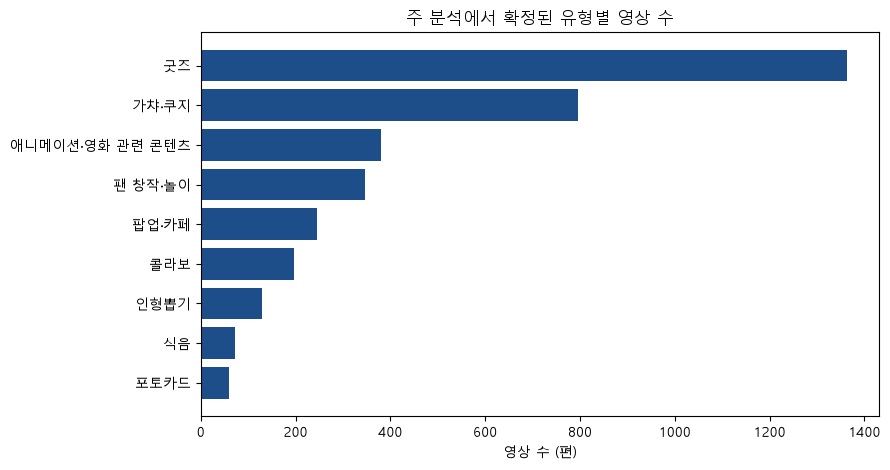

In [5]:
n_main = len(main)
print("주 분석", n_main, "조회수", int(main["view_count"].sum()))
print("미분류", int(main["type_confirmed"].eq("").sum()), f"({main['type_confirmed'].eq('').mean():.3f})")

rows = []
for label in rules.V3_TYPES:
    mask = main["type_confirmed"].str.contains(label, regex=False)
    part = main.loc[mask]
    rows.append({
        "유형": label,
        "영상 수": int(mask.sum()),
        "주 분석 대비": round(mask.mean(), 3),
        "조회수 중앙값": part["view_count"].median(),
        "좋아요율 중앙값": part["like_rate"].median(),
        "좋아요율 계산 가능": int(part["like_rate"].notna().sum()),
        "댓글률 중앙값": part["comment_rate"].median(),
        "댓글률 계산 가능": int(part["comment_rate"].notna().sum()),
        "참여율 중앙값": part["engagement_rate"].median(),
        "참여율 계산 가능": int(part["engagement_rate"].notna().sum()),
    })
type_summary = pd.DataFrame(rows)
print(type_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_df = type_summary.sort_values("영상 수", ascending=True)
ax.barh(plot_df["유형"], plot_df["영상 수"], color="#1d4e89")
ax.set_xlabel("영상 수 (편)")
ax.set_title("주 분석에서 확정된 유형별 영상 수")
fig.tight_layout()
plt.show()


      주 분석    보류
year            
2022   362  1531
2023  1220  1566
2024  1782   879
2025  1223  1578
2026  1985   785
주 분석에서 2026년 마지막 게시 2026-10-26 19:00:08+09:00


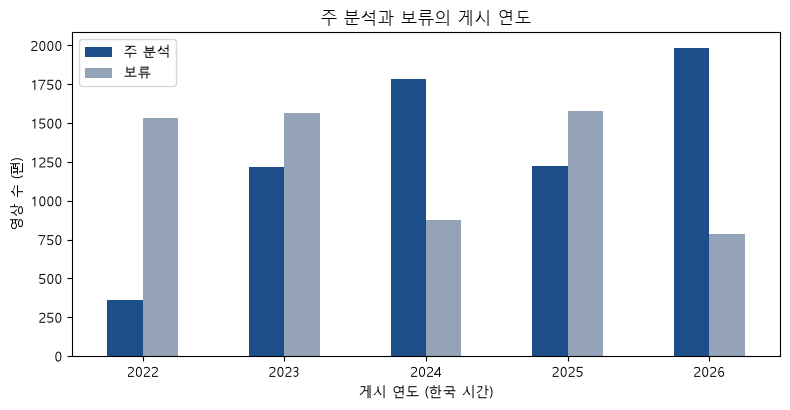

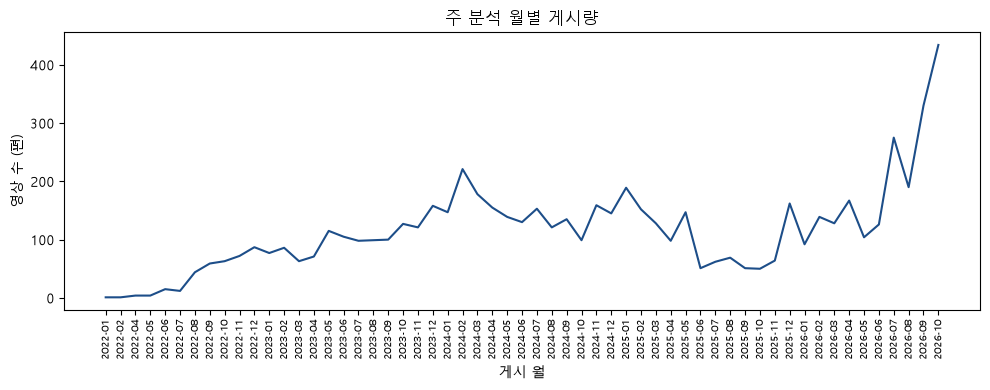

In [6]:
yearly = main.groupby("year").size().rename("주 분석")
hold_year = hold.groupby("year").size().rename("보류")
year_cmp = pd.concat([yearly, hold_year], axis=1).fillna(0).astype(int)
print(year_cmp.to_string())
max_2026 = main.loc[main["year"].eq(2026), "publish_at_kst"].max()
print("주 분석에서 2026년 마지막 게시", max_2026)

fig, ax = plt.subplots(figsize=(8, 4.2))
year_cmp.plot(kind="bar", ax=ax, color=["#1d4e89", "#94a3b8"], rot=0)
ax.set_xlabel("게시 연도 (한국 시간)")
ax.set_ylabel("영상 수 (편)")
ax.set_title("주 분석과 보류의 게시 연도")
fig.tight_layout()
plt.show()

monthly = main.groupby("year_month").size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, color="#1d4e89")
ax.set_title("주 분석 월별 게시량")
ax.set_xlabel("게시 월")
ax.set_ylabel("영상 수 (편)")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
fig.tight_layout()
plt.show()


주 분석 채널 2973
             channel  게시수       수집조회수
              AniBox  383 176401890.0
                성우전쟁   18  26081092.0
              오늘은뭐볼까   17  16450750.0
                 마금이   12  16155403.0
                 C급쇼   10  15696541.0
                 쇼도독    4  14645348.0
                박노강이   14  13345604.0
외줄집사 Singleline_cafe    5  12650652.0
         대원미디어DAEWON   14  11771256.0
                 강브레   13  10554879.0
상위 10채널 조회수 비중 0.516

수집 표본 안 첫 등장 연도
year
2022    168
2023    540
2024    774
2025    613
2026    878


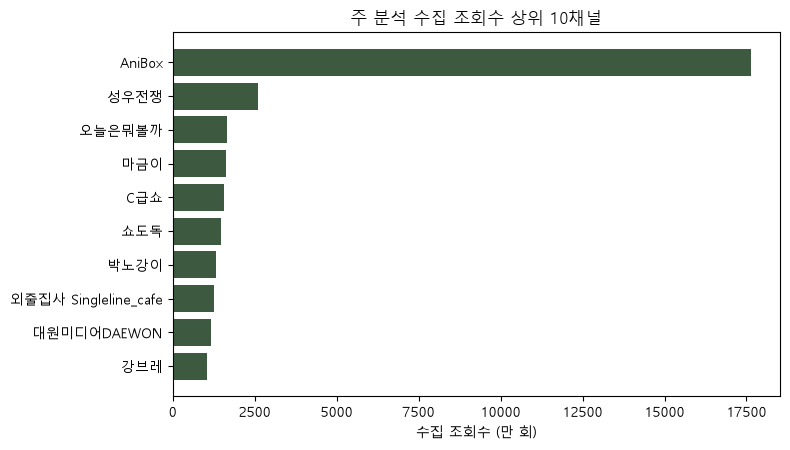

In [7]:
channel_stats = main.groupby(["channel_id", "channel"]).agg(게시수=("video_id", "size"), 수집조회수=("view_count", "sum")).reset_index()
top10 = channel_stats.sort_values("수집조회수", ascending=False).head(10)
print("주 분석 채널", channel_stats["channel_id"].nunique())
print(top10[["channel", "게시수", "수집조회수"]].to_string(index=False))
print("상위 10채널 조회수 비중", round(top10["수집조회수"].sum() / main["view_count"].sum(), 3))
first_year = main.groupby("channel_id")["year"].min().value_counts().sort_index()
print("\n수집 표본 안 첫 등장 연도")
print(first_year.to_string())

fig, ax = plt.subplots(figsize=(8, 4.6))
show = top10.sort_values("수집조회수", ascending=True)
ax.barh(show["channel"], show["수집조회수"] / 10000, color="#3d5a40")
ax.set_xlabel("수집 조회수 (만 회)")
ax.set_title("주 분석 수집 조회수 상위 10채널")
fig.tight_layout()
plt.show()


## 보류를 빼면 무엇이 달라지나

보류에는 해시태그만으로 명칭이 붙은 영상과, 한국어 문장은 있지만 작품 관련을 확정하지 못한 영상이 함께 있다. 조회수가 여기에 몰리면 주 분석의 반응 수치는 텍스트로 확인된 영상 쪽으로 기울다.


In [8]:
bias = pd.DataFrame({
    "구분": ["주 분석", "보류", "제외"],
    "영상 수": [len(main), len(hold), len(dropped)],
    "조회수": [main["view_count"].sum(), hold["view_count"].sum(), dropped["view_count"].sum()],
})
bias["영상 비율"] = (bias["영상 수"] / len(work)).round(3)
bias["조회수 비율"] = (bias["조회수"] / work["view_count"].sum()).round(3)
print(bias.to_string(index=False))

cand_rows = []
for label in rules.V3_TYPES:
    cand_rows.append({
        "후보 유형": label,
        "주 분석 후보": int(main["type_candidates"].str.contains(label, regex=False).sum()),
        "보류 후보": int(hold["type_candidates"].str.contains(label, regex=False).sum()),
        "주 분석 확정": int(main["type_confirmed"].str.contains(label, regex=False).sum()),
    })
print("\n키워드 후보와 확정. 보류의 후보는 확정 유형이 아니다")
print(pd.DataFrame(cand_rows).to_string(index=False))


  구분  영상 수         조회수  영상 비율  조회수 비율
주 분석  6572 607500005.0  0.491   0.344
  보류  6339 585587490.0  0.474   0.332
  제외   472 571002212.0  0.035   0.324

키워드 후보와 확정. 보류의 후보는 확정 유형이 아니다
          후보 유형  주 분석 후보  보류 후보  주 분석 확정
             굿즈     1875    392     1363
           포토카드      143    103       60
          가챠·쿠지     1123    170      796
           인형뽑기      227     83      129
애니메이션·영화 관련 콘텐츠      476     11      381
          팝업·카페      255     16      246
             식음      171     31       73
            콜라보      201      7      197
        팬 창작·놀이      466   1548      347


## 문자열 언급은 소비도 유형 확정도 아니다

아래는 주 분석 제목에서 두 글자 이상 한글이 연속된 횟수다. 같은 제목에서 반복되면 여러 번 센다. 영상 수도 아니고, 구매·방문·시청도 아니다.


In [9]:
tokens = main["title"].fillna("").str.findall(r"[가-힣]{2,}").explode()
token_counts = tokens.value_counts().head(20).rename("제목 단어 출현 횟수").rename_axis("문자열").reset_index()
print(token_counts.to_string(index=False))


 문자열  제목 단어 출현 횟수
치이카와         6695
 먼작귀         2147
 우사기          495
하치와레          449
  가챠          415
 귀여운          404
브이로그          391
 랜덤깡          329
 산리오          317
 언박싱          313
 피규어          279
  작고          273
  굿즈          270
  먼가          259
  일본          256
 오타쿠          255
  뽑기          247
  녀석          247
 만들기          243
  인형          242


## 읽는 기준

텍스트로 말할 수 있는 것

- 주 분석에 들어간 영상은 제목이나 설명에 작품·캐릭터를 다루는 문장과 한국어 서술이 있다.
- 제외는 사용자 확인으로 무관하거나, 한국어 서술 없이 다른 언어·공식 일본어 방송·다른 IP 제목이 있는 경우다.
- 보류는 무관이 아니다. 해시태그만 있는 고조회수 영상이 여기 많이 남는다.
- 확정 유형은 제목 본문이 그 활동을 말할 때로 제한했다. 후보 키워드 수보다 적다.

이 노트북만으로 말하지 않는 것

- 조회수가 한국에서 발생한 양
- 유형 영상 수가 판매량이나 방문 수
- 캐릭터 이름 횟수가 선호도
- 반응률 차이가 인기의 원인

더 보려면 필요한 자료

- 시청자 국가별 조회수
- 제작자가 넣은 자막과 자동 번역의 구분
- 보류 영상, 특히 해시태그만 있는 고조회수 영상의 화면 확인


In [10]:
assert source_rows == 13383
assert source_like_na == 743
assert source_comment_na == 1265
assert int(pd.read_csv(analysis_path, encoding="utf-8-sig")["like_count"].isna().sum()) == source_like_na
assert work["video_id"].is_unique
assert set(work["disposition"]) <= {"포함", "보류", "제외"}
assert len(main) + len(hold) + len(dropped) == len(work)
assert (main["relevance"].eq("관련") & main["audience"].eq("확인")).all()
assert work.loc[work["relevance"].ne("관련"), "type_confirmed"].eq("").all()
hash_only = work["hashtags"].str.contains("인형계") & ~work["title_body"].str.contains("인형계")
other_play = work["title_body"].str.contains(r"더빙|팬아트|그리기|만들기")
assert not work.loc[hash_only & ~other_play, "type_confirmed"].str.contains("팬 창작·놀이").fillna(False).any()
print("원본 행·결측 유지, 판정 분할, 해시태그 인형계 미확정")
print("분석 대상 relevant", len(work), "/ 주 분석", len(main), "/ 보류", len(hold), "/ 제외", len(dropped))


원본 행·결측 유지, 판정 분할, 해시태그 인형계 미확정
분석 대상 relevant 13383 / 주 분석 6572 / 보류 6339 / 제외 472
